<a href="https://colab.research.google.com/github/ayush123-45/redwine-quality_prediction/blob/main/Red_Wine_Quality_ML_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Red Wine Quality Prediction Using Machine Learning

**Project aim:** Use wine measurements to predict its quality score.

This is a beginner-friendly project designed for Google Colab. It uses common libraries and four models that are useful for this dataset:
- Linear Regression
- Ridge Regression
- Decision Tree Regressor
- Random Forest Regressor

We will compare the models using MAE, RMSE and R², then choose the best one based on the test results.

## Step 1: Import the required libraries

In [ ]:
# These libraries are commonly used in beginner-level machine learning projects.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## Step 2: Upload and read the dataset

In [ ]:
# Run this cell and select your winequality-red.csv file.
uploaded = files.upload()

# Read the uploaded CSV file into a DataFrame.
file_name = list(uploaded.keys())[0]
df = pd.read_csv(file_name)

# Remove extra spaces from column names, if any.
df.columns = df.columns.str.strip()

print("Dataset size:", df.shape)
display(df.head())

Saving red_wine.csv - winequality-red.csv to red_wine.csv - winequality-red.csv
Dataset size: (12435, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


## Step 3: Understanding the data

In [ ]:
# Check column names, data types and missing values.
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nSummary of numerical columns:")
display(df.describe())

print("\nMissing values in each column:")
display(df.isnull().sum())

print("\nNumber of duplicate rows:", df.duplicated().sum())

Column names:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12435 entries, 0 to 12434
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         12435 non-null  float64
 1   volatile acidity      12435 non-null  float64
 2   citric acid           12435 non-null  float64
 3   residual sugar        12435 non-null  float64
 4   chlorides             12435 non-null  float64
 5   free sulfur dioxide   12435 non-null  float64
 6   total sulfur dioxide  12435 non-null  float64
 7   density               12435 non-null  float64
 8   pH                    12435 non-null  float64
 9   sulphates             12435 non-null  float64
 10  alcohol               12435 non-null  float64
 11  qual

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,12435.000000,12435.000000,12435.000000,12435.000000,12435.000000,12435.000000,12435.000000,12435.000000,12435.000000,12435.000000,12435.000000,12435.000000
mean,8.322805,0.530524,0.274926,2.616837,0.088534,16.304501,47.751522,0.996759,3.311336,0.659797,10.442361,5.636429
std,1.720663,0.177655,0.182415,1.288746,0.044907,9.942896,30.032373,0.001907,0.153886,0.166133,1.041664,0.809173
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.137249,0.406742,0.130000,1.676913,0.059575,8.644366,23.875352,0.995507,3.208250,0.547211,9.684186,5.000000
50%,8.260570,0.529856,0.267815,2.455688,0.085000,15.742866,45.142427,0.996758,3.310000,0.652928,10.412255,6.000000
75%,9.461616,0.650000,0.403444,3.407927,0.115287,23.033076,67.410135,0.998004,3.412571,0.769328,11.129480,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000



Missing values in each column:


,0
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0



Number of duplicate rows: 240


## Step 4: Cleaning the data

In [ ]:

df = df.dropna(subset=["quality"]).copy()


df = df.drop_duplicates().copy()


for column in df.columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")


df = df.dropna(subset=["quality"]).copy()



for column in df.columns:
    if column != "quality":
        df[column] = df[column].fillna(df[column].median())

print("Dataset size after cleaning:", df.shape)
print("Remaining missing values:", int(df.isnull().sum().sum()))

Dataset size after cleaning: (12195, 12)
Remaining missing values: 0


 (EDA)

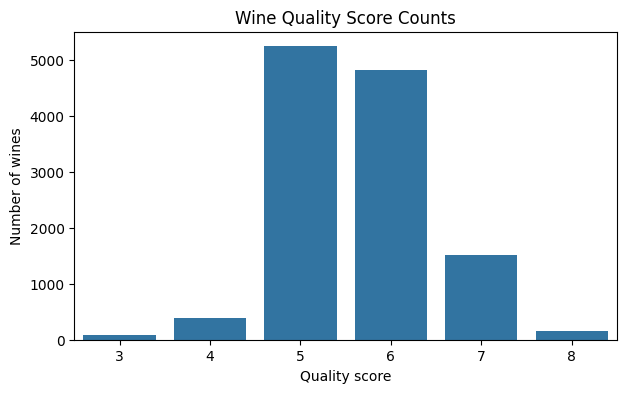

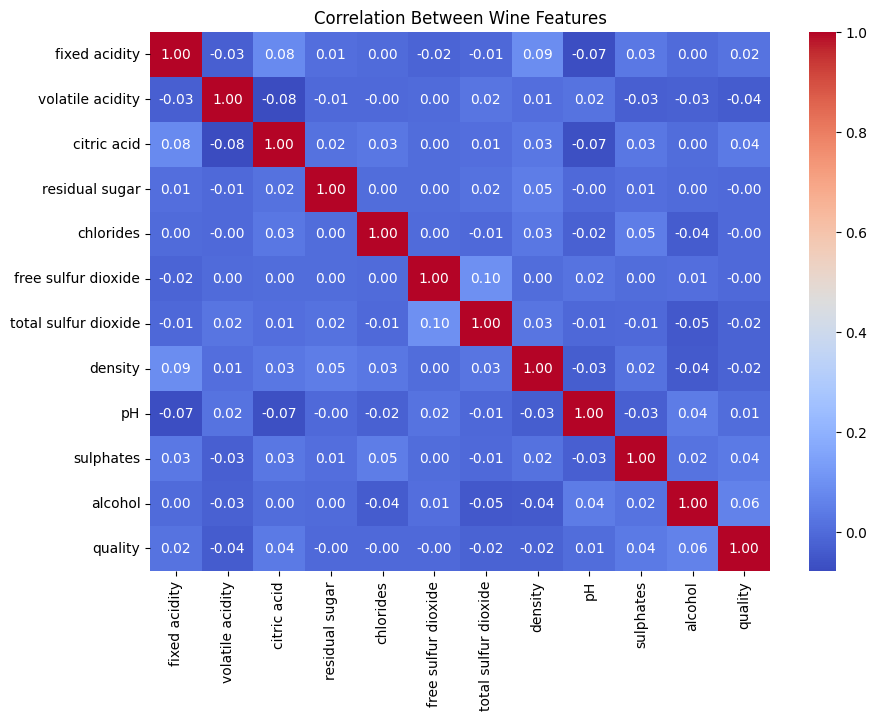

,Correlation with quality
alcohol,0.058555
citric acid,0.040312
sulphates,0.038711
volatile acidity,-0.035664
fixed acidity,0.022570
total sulfur dioxide,-0.021844
density,-0.021477
pH,0.006492
chlorides,-0.004418
free sulfur dioxide,-0.002784


In [ ]:
# See how frequently each wine quality score occurs.
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="quality")
plt.title("Wine Quality Score Counts")
plt.xlabel("Quality score")
plt.ylabel("Number of wines")
plt.show()

# Look at the relationship between features and quality.
plt.figure(figsize=(10, 7))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between Wine Features")
plt.show()

# Show which features have the strongest positive or negative correlation with quality.
correlations = df.corr(numeric_only=True)["quality"].drop("quality")
correlations = correlations.sort_values(key=abs, ascending=False)
display(correlations.to_frame("Correlation with quality"))

## Step 6: Separate features and target

In [ ]:


X = df.drop("quality", axis=1)
y = df["quality"]
.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 9756
Testing records: 2439


## Step 7: Train four useful models

In [ ]:

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)


ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train, y_train)

tree_model = DecisionTreeRegressor(max_depth=6, random_state=42)
tree_model.fit(X_train, y_train)

forest_model = RandomForestRegressor(
    n_estimators=100, max_depth=10, random_state=42
)
forest_model.fit(X_train, y_train)

print("All four models have been trained.")

All four models have been trained.


## Step 8: Compare model performance

In [ ]:
# Get predictions from each trained model.
predictions = {
    "Linear Regression": linear_model.predict(X_test),
    "Ridge Regression": ridge_model.predict(X_test),
    "Decision Tree": tree_model.predict(X_test),
    "Random Forest": forest_model.predict(X_test)
}

# Calculate the same evaluation scores for every model.
results = []

for model_name, predicted_values in predictions.items():
    mae = mean_absolute_error(y_test, predicted_values)
    rmse = np.sqrt(mean_squared_error(y_test, predicted_values))
    r2 = r2_score(y_test, predicted_values)

    results.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

results_df = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)
display(results_df.round(3))

# The model with the lowest RMSE is selected as the best model for this test split.
best_model_name = results_df.loc[0, "Model"]
print("Best model based on the lowest RMSE:", best_model_name)

,Model,MAE,RMSE,R2 Score
0,Random Forest,0.662,0.786,0.012
1,Linear Regression,0.667,0.789,0.005
2,Ridge Regression,0.667,0.789,0.005
3,Decision Tree,0.677,0.812,-0.053


Best model based on the lowest RMSE: Random Forest


## Step 9: Plot actual and predicted scores for the best model

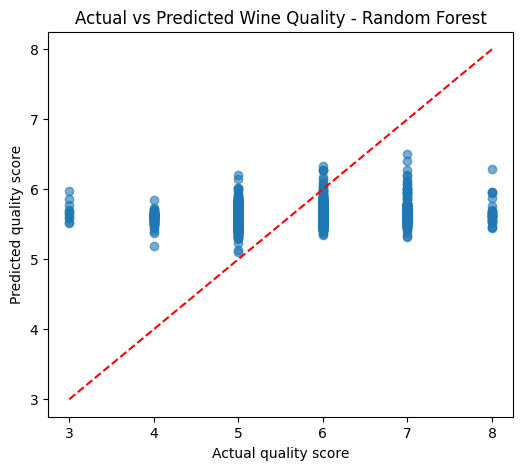

In [ ]:

best_predictions = predictions[best_model_name]

plt.figure(figsize=(6, 5))
plt.scatter(y_test, best_predictions, alpha=0.6)
plt.xlabel("Actual quality score")
plt.ylabel("Predicted quality score")
plt.title("Actual vs Predicted Wine Quality - " + best_model_name)

# A point close to this line means the prediction is close to the actual score.
lower = min(y_test.min(), best_predictions.min())
upper = max(y_test.max(), best_predictions.max())
plt.plot([lower, upper], [lower, upper], "r--")
plt.show()

## Step 10: Checking feature importance

,Feature importance
alcohol,0.107855
volatile acidity,0.103865
sulphates,0.095326
citric acid,0.095269
density,0.094213
fixed acidity,0.090208
chlorides,0.089419
pH,0.086666
total sulfur dioxide,0.083893
free sulfur dioxide,0.077706


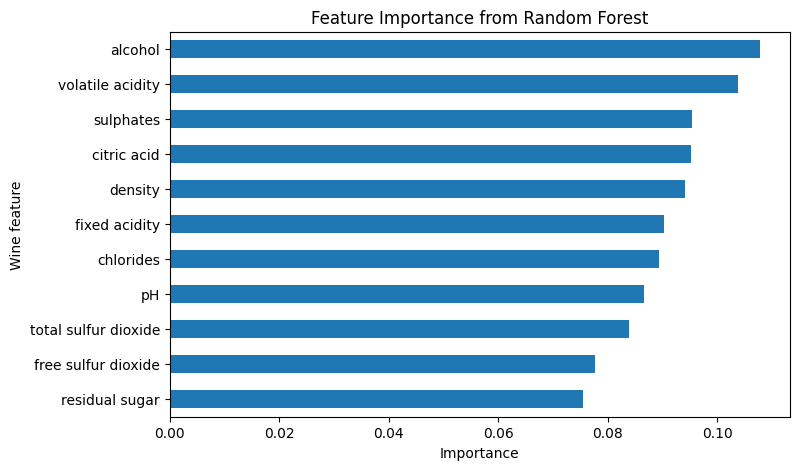

In [ ]:

importance = pd.Series(
    forest_model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

display(importance.to_frame("Feature importance"))

plt.figure(figsize=(8, 5))
importance.sort_values().plot(kind="barh")
plt.title("Feature Importance from Random Forest")
plt.xlabel("Importance")
plt.ylabel("Wine feature")
plt.show()

In [ ]:

sample_wine = X_test.iloc[[0]]


if best_model_name == "Linear Regression":
    best_model = linear_model
elif best_model_name == "Ridge Regression":
    best_model = ridge_model
elif best_model_name == "Decision Tree":
    best_model = tree_model
else:
    best_model = forest_model

predicted_quality = best_model.predict(sample_wine)[0]

print("Wine measurements:")
display(sample_wine)

print("Actual quality:", y_test.iloc[0])
print("Predicted quality:", round(float(predicted_quality), 2))
print("Rounded predicted score:", int(np.rint(predicted_quality)))

Wine measurements:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
5940,8.65375,0.618539,0.282054,4.679135,0.030893,16.414652,70.610456,0.996587,3.481162,0.676869,11.156805


Actual quality: 7
Predicted quality: 5.69
Rounded predicted score: 6
